# Análisis de ventas: US Superstore

Análisis exploratorio de las ventas de una tienda minorista de EE. UU. entre 2014 y 2017: tendencias, categorías, envíos y ciudades.

## Librerías

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xlrd


## Carga de datos

In [77]:
data = pd.read_excel("C:\\Users\\ASUS\\Documents\\VS code\\Data Analysis\\US Superstore data.xls")
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [78]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

## Variables de fecha y ventas totales

In [79]:
data["year_order"] = data["Order Date"].dt.year
data["month_order"] = data["Order Date"].dt.month
data["day_order"] = data["Order Date"].dt.day

data["year_ship"] = data["Ship Date"].dt.year
data["month_ship"] = data["Ship Date"].dt.month
data["day_ship"] = data["Ship Date"].dt.day

In [80]:
data["total_sales"] = data["Sales"] * data["Quantity"] * (1 - data["Discount"])

**Nota sobre `total_sales`:** en este dataset la columna `Sales` ya viene como el total de la línea (cantidad y descuento incluidos). Lo comprobamos: para un mismo producto, `Sales / (Quantity * (1 - Discount))` es constante, o sea que es el precio unitario de lista.

In [81]:
multi = data.groupby("Product ID").filter(lambda g: len(g) >= 5)
precio_unitario = multi["Sales"] / (multi["Quantity"] * (1 - multi["Discount"]))
cv = precio_unitario.groupby(multi["Product ID"]).std() / precio_unitario.groupby(multi["Product ID"]).mean()
print("Variación mediana del precio unitario implícito:", round(cv.median(), 4))
print("Suma de Sales:", round(data["Sales"].sum()))
print("Suma de total_sales:", round(data["total_sales"].sum()))

Variación mediana del precio unitario implícito: 0.0
Suma de Sales: 2297201
Suma de total_sales: 9894184


Por eso, en las secciones nuevas más abajo se usa `Sales` directamente (junto con `Profit`) para ventas, utilidad y margen.

In [82]:
data.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Quantity,Discount,Profit,year_order,month_order,day_order,year_ship,month_ship,day_ship,total_sales
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,2,0.00,41.9136,2016,11,8,2016,11,11,523.920000
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,3,0.00,219.5820,2016,11,8,2016,11,11,2195.820000
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,2,0.00,6.8714,2016,6,12,2016,6,16,29.240000
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,5,0.45,-383.0310,2015,10,11,2015,10,18,2633.338125
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,2,0.20,2.5164,2015,10,11,2015,10,18,35.788800


## Tendencias en el tiempo

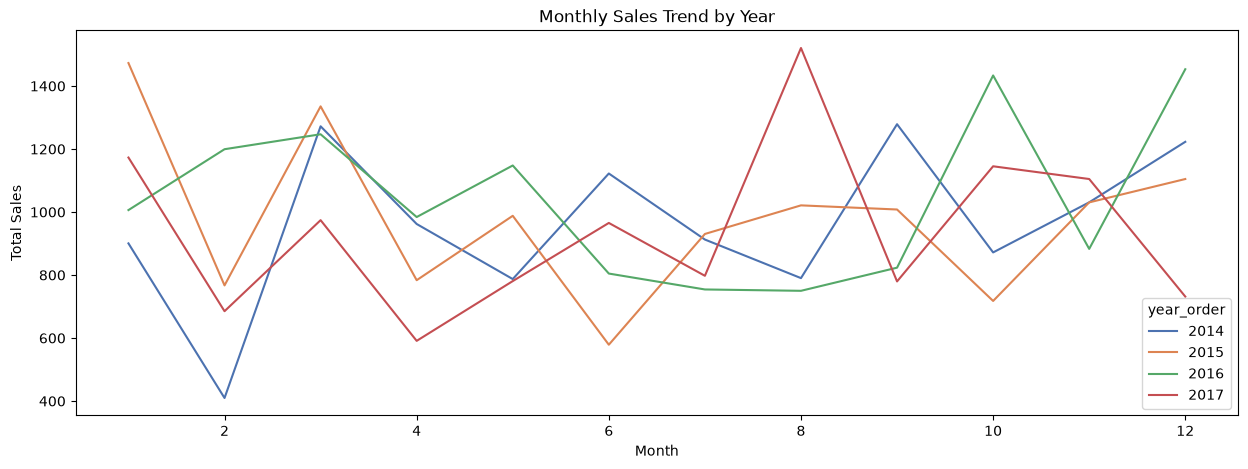

In [83]:
plt.figure(figsize=(15, 5))
sns.lineplot(data=data, x="month_order", y="total_sales", hue="year_order", palette="deep", errorbar=None)
plt.title("Monthly Sales Trend by Year")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

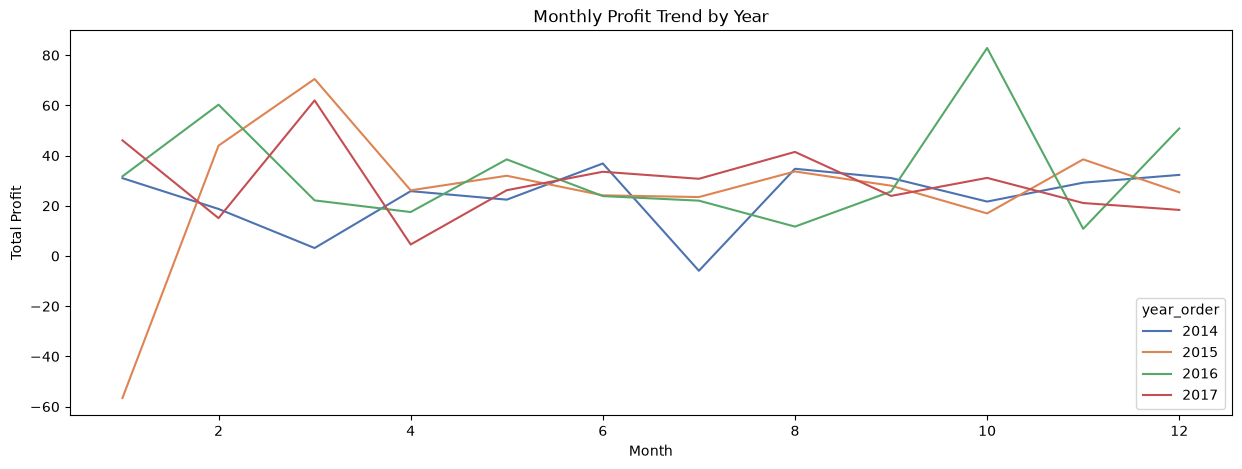

In [84]:
plt.figure(figsize=(15, 5))
sns.lineplot(data=data, x="month_order", y="Profit", hue="year_order", palette="deep", errorbar=None)
plt.title("Monthly Profit Trend by Year")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.show()

Text(0.5, 1.0, 'Average Total Sales by Year')

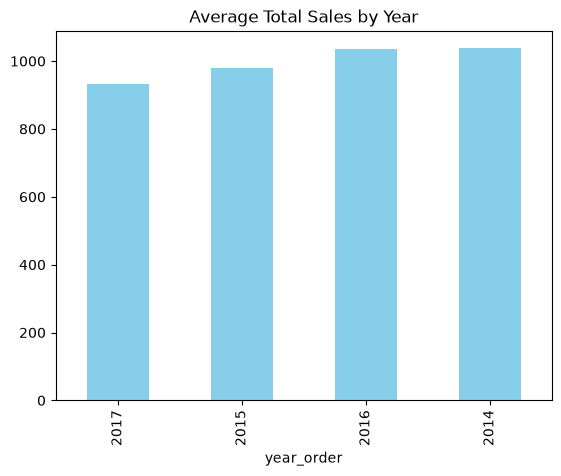

In [85]:
data.groupby("year_order")["total_sales"].mean().sort_values(ascending=True).plot(kind="bar", color="skyblue")
plt.title("Average Total Sales by Year")

## Categorías y subcategorías

In [86]:
data["Category"].value_counts()

Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

In [87]:
data["Sub-Category"].value_counts()

Sub-Category
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64

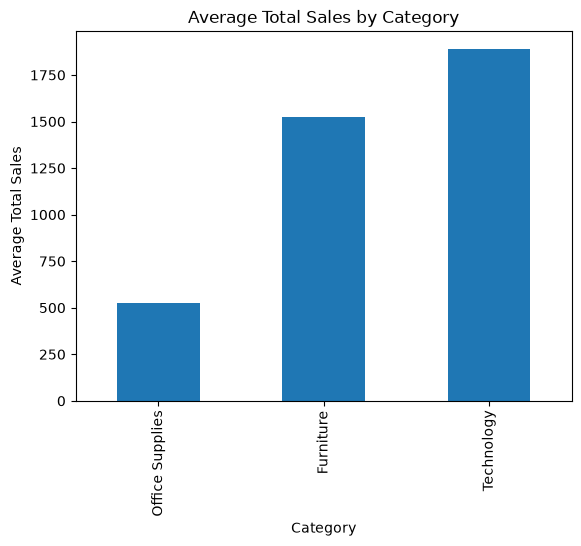

In [88]:
data.groupby("Category")["total_sales"].mean().sort_values(ascending=True).plot(kind="bar")
plt.title("Average Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Average Total Sales")
plt.show()

<Axes: xlabel='Sub-Category'>

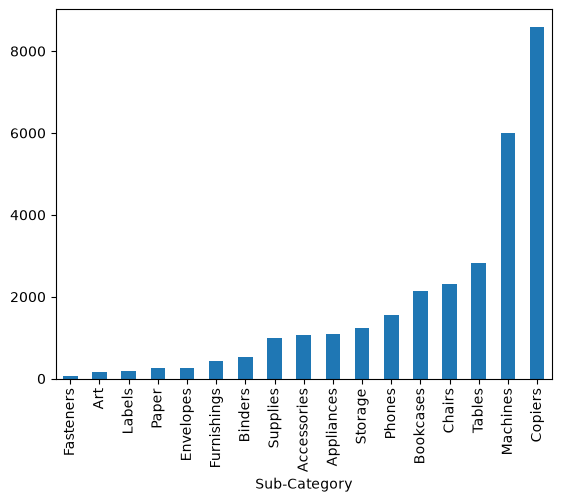

In [89]:
data.groupby("Sub-Category")["total_sales"].mean().sort_values(ascending=True).plot(kind="bar")

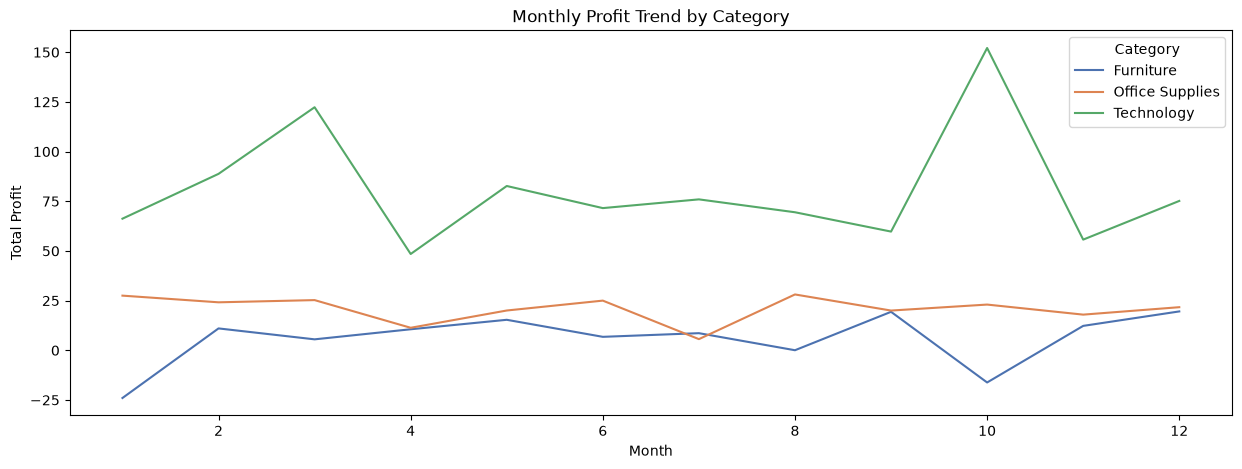

In [90]:
plt.figure(figsize=(15, 5))
sns.lineplot(data=data, x="month_order", y="Profit", hue="Category", palette="deep", errorbar=None)
plt.title("Monthly Profit Trend by Category")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.show()

## Tiempo de envío

In [91]:
data["tiempo_envio"] = (data["Ship Date"] - data["Order Date"]).dt.days
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Discount,Profit,year_order,month_order,day_order,year_ship,month_ship,day_ship,total_sales,tiempo_envio
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0.00,41.9136,2016,11,8,2016,11,11,523.920000,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,0.00,219.5820,2016,11,8,2016,11,11,2195.820000,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,0.00,6.8714,2016,6,12,2016,6,16,29.240000,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0.45,-383.0310,2015,10,11,2015,10,18,2633.338125,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,0.20,2.5164,2015,10,11,2015,10,18,35.788800,7


In [92]:
tiempo_envio_mensual = data.groupby(pd.Grouper(key="Order Date", freq="ME"))["tiempo_envio"].mean().reset_index()
tiempo_envio_mensual["month"] = tiempo_envio_mensual["Order Date"].dt.strftime("%Y-%m")
tiempo_envio_mensual.head()

,Order Date,tiempo_envio,month
0,2014-01-31,4.164557,2014-01
1,2014-02-28,4.173913,2014-02
2,2014-03-31,3.974522,2014-03
3,2014-04-30,4.051852,2014-04
4,2014-05-31,3.803279,2014-05


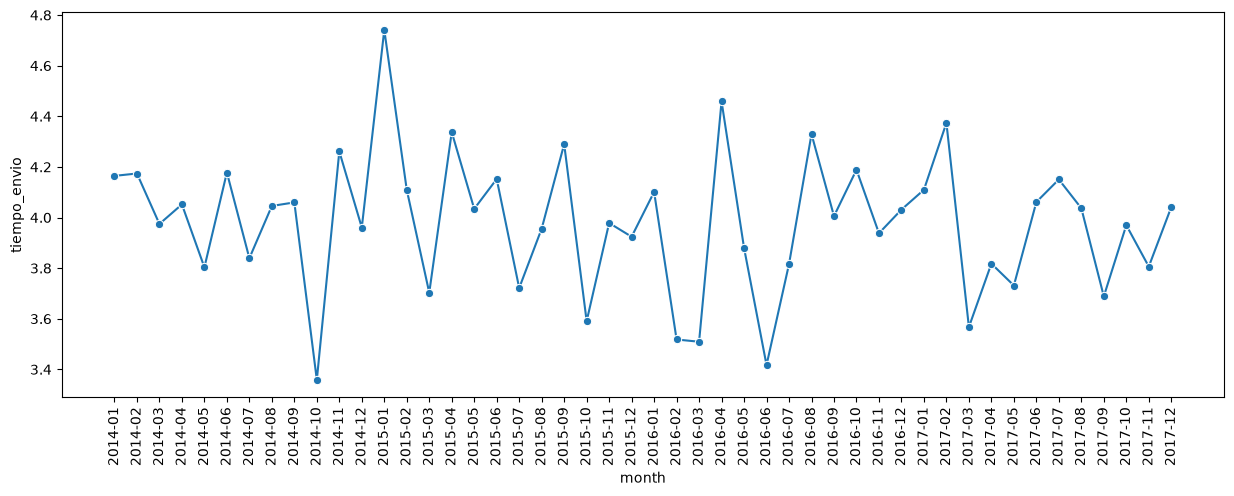

In [93]:
plt.figure(figsize=(15, 5))
sns.lineplot(data=tiempo_envio_mensual, x="month", y="tiempo_envio", marker="o")
plt.xticks(rotation=90)
plt.show()

## Ciudades y trimestres

<Axes: xlabel='City'>

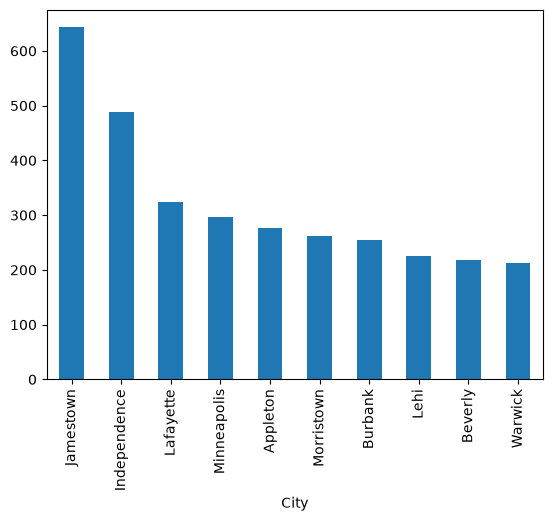

In [94]:
data.groupby("City")["Profit"].mean().sort_values(ascending=False).head(10).plot(kind="bar")

In [95]:
data["Quarter"] = data["Order Date"].dt.quarter


In [96]:
ventas_trimestre = data.groupby(["year_order", "Quarter"])["total_sales"].sum().reset_index()
ventas_trimestre.head()

,year_order,Quarter,total_sales
0,2014,1,289702.847750
1,2014,2,377424.189382
2,2014,3,594115.575133
3,2014,4,806349.253526
4,2015,1,318803.586316


<Axes: xlabel='Quarter', ylabel='total_sales'>

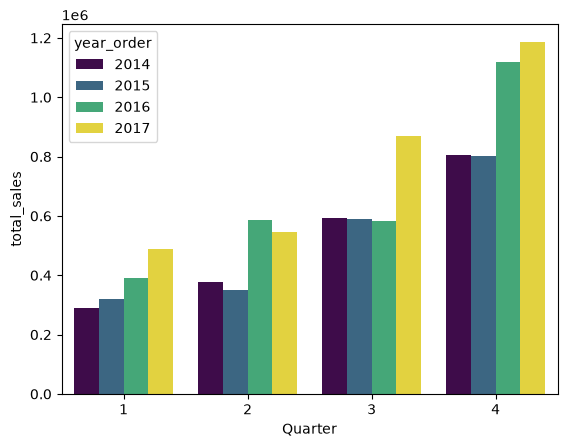

In [97]:
sns.barplot(data=ventas_trimestre, x="Quarter", y="total_sales", hue="year_order", palette="viridis")

## Resumen general

Primero unos números generales: ventas, utilidad, margen, pedidos y clientes.

In [98]:
resumen = pd.Series({
    "Ventas (Sales)": data["Sales"].sum(),
    "Utilidad (Profit)": data["Profit"].sum(),
    "Margen": data["Profit"].sum() / data["Sales"].sum(),
    "Pedidos": data["Order ID"].nunique(),
    "Clientes": data["Customer ID"].nunique(),
    "Descuento promedio": data["Discount"].mean(),
})
resumen

Ventas (Sales)        2.297201e+06
Utilidad (Profit)     2.863970e+05
Margen                1.246722e-01
Pedidos               5.009000e+03
Clientes              7.930000e+02
Descuento promedio    1.562027e-01
dtype: float64

In [99]:
anual = data.groupby("year_order").agg(ventas=("Sales", "sum"), utilidad=("Profit", "sum"))
anual["margen"] = anual["utilidad"] / anual["ventas"]
anual["crecimiento_ventas"] = anual["ventas"].pct_change()
anual

,ventas,utilidad,margen,crecimiento_ventas
year_order,,,,
2014,484247.4981,49543.9741,0.102311,NaN
2015,470532.5090,61618.6037,0.130955,-0.028322
2016,609205.5980,81795.1743,0.134265,0.294715
2017,733215.2552,93439.2696,0.127438,0.203560


## Ventas y utilidad por categoría y subcategoría

Antes se miró el promedio por línea de pedido. Aquí se ven los totales y el margen (utilidad / ventas).

In [100]:
cat = data.groupby("Category").agg(ventas=("Sales", "sum"), utilidad=("Profit", "sum"))
cat["margen"] = cat["utilidad"] / cat["ventas"]
cat

,ventas,utilidad,margen
Category,,,
Furniture,741999.7953,18451.2728,0.024867
Office Supplies,719047.0320,122490.8008,0.170352
Technology,836154.0330,145454.9481,0.173957


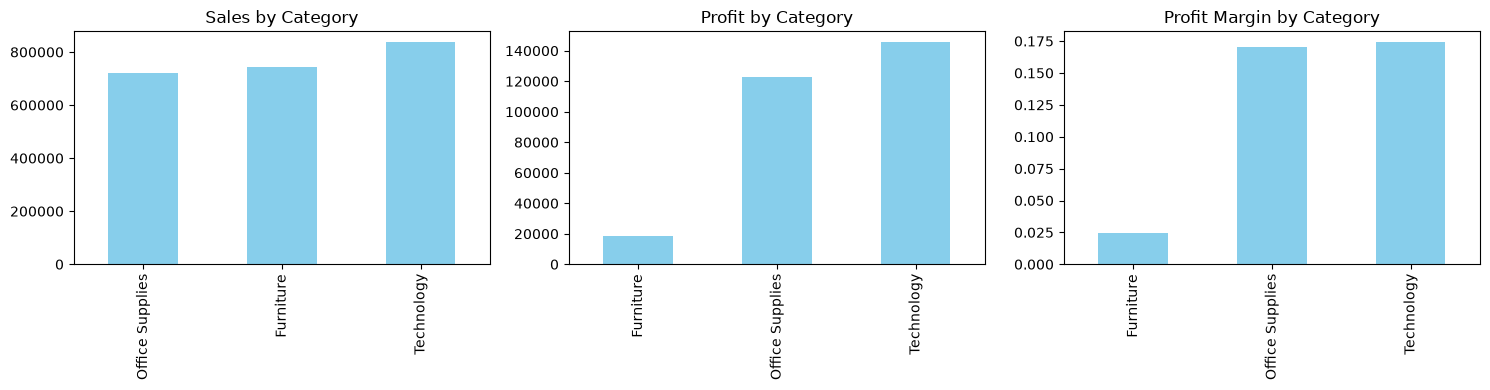

In [101]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, titulo in zip(axes, ["ventas", "utilidad", "margen"], ["Sales", "Profit", "Profit Margin"]):
    cat[col].sort_values().plot(kind="bar", ax=ax, color="skyblue")
    ax.set_title(f"{titulo} by Category")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

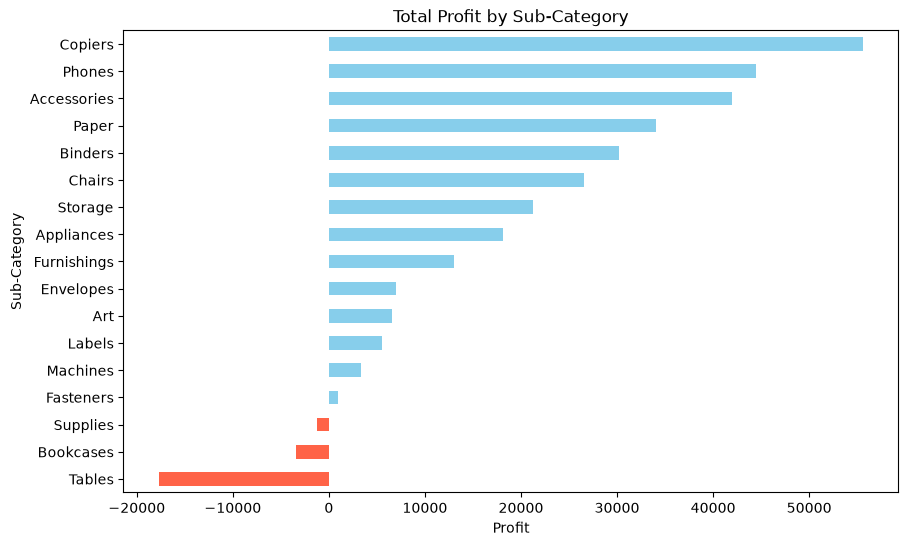

,ventas,utilidad,margen
Sub-Category,,,
Tables,206965.5320,-17725.4811,-0.085645
Bookcases,114879.9963,-3472.5560,-0.030228
Supplies,46673.5380,-1189.0995,-0.025477
Fasteners,3024.2800,949.5182,0.313965
Machines,189238.6310,3384.7569,0.017886


In [102]:
sub = data.groupby("Sub-Category").agg(ventas=("Sales", "sum"), utilidad=("Profit", "sum"))
sub["margen"] = sub["utilidad"] / sub["ventas"]

plt.figure(figsize=(10, 6))
sub["utilidad"].sort_values().plot(kind="barh", color=["tomato" if v < 0 else "skyblue" for v in sub["utilidad"].sort_values()])
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit")
plt.show()

sub.sort_values("utilidad").head(5)

## Efecto de los descuentos

Algunas subcategorías pierden dinero. Una posible causa son los descuentos, así que se compara la utilidad según el nivel de descuento.

In [103]:
data["tramo_descuento"] = pd.cut(data["Discount"], bins=[-0.001, 0, 0.2, 0.4, 1],
                                 labels=["0%", "1-20%", "21-40%", ">40%"])
desc = data.groupby("tramo_descuento", observed=True).agg(lineas=("Sales", "size"), ventas=("Sales", "sum"), utilidad=("Profit", "sum"))
desc["margen"] = desc["utilidad"] / desc["ventas"]
desc

,lineas,ventas,utilidad,margen
tramo_descuento,,,,
0%,4798,1.087908e+06,320987.6032,0.295050
1-20%,3803,8.465222e+05,100785.4745,0.119058
21-40%,460,2.341379e+05,-35817.4655,-0.152976
>40%,933,1.286323e+05,-99558.5905,-0.773978


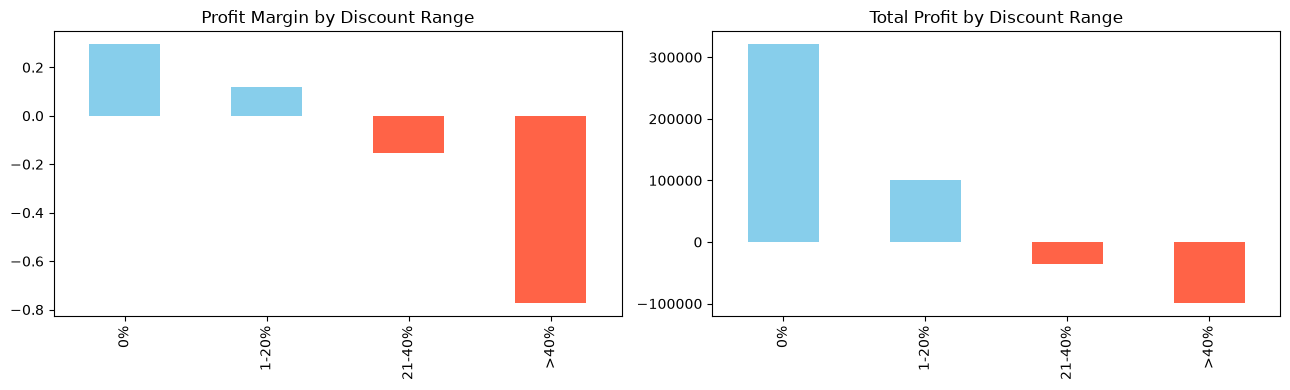

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
desc["margen"].plot(kind="bar", ax=axes[0], color=["skyblue" if v > 0 else "tomato" for v in desc["margen"]])
axes[0].set_title("Profit Margin by Discount Range")
axes[0].set_xlabel("")
desc["utilidad"].plot(kind="bar", ax=axes[1], color=["skyblue" if v > 0 else "tomato" for v in desc["utilidad"]])
axes[1].set_title("Total Profit by Discount Range")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

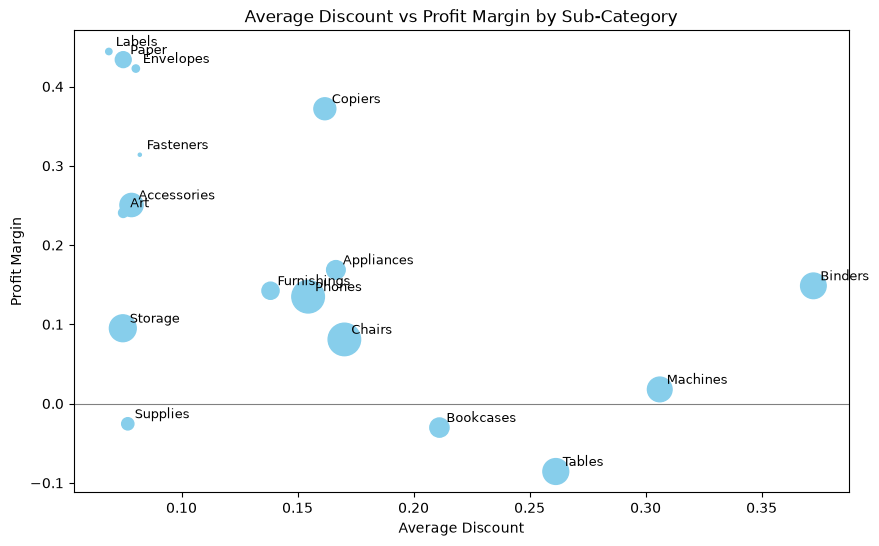

Correlación Discount vs Profit: -0.22


In [105]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(data.groupby("Sub-Category")["Discount"].mean(), sub["margen"], s=sub["ventas"] / 600, color="skyblue")
for nombre in sub.index:
    ax.annotate(nombre, (data[data["Sub-Category"] == nombre]["Discount"].mean(), sub.loc[nombre, "margen"]),
                xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.axhline(0, color="gray", lw=0.8)
ax.set_title("Average Discount vs Profit Margin by Sub-Category")
ax.set_xlabel("Average Discount")
ax.set_ylabel("Profit Margin")
plt.show()

print("Correlación Discount vs Profit:", round(data["Discount"].corr(data["Profit"]), 2))

## Región, estado y segmento

In [106]:
region = data.groupby("Region").agg(ventas=("Sales", "sum"), utilidad=("Profit", "sum"), descuento_prom=("Discount", "mean"))
region["margen"] = region["utilidad"] / region["ventas"]
region.sort_values("utilidad", ascending=False)

,ventas,utilidad,descuento_prom,margen
Region,,,,
West,725457.8245,108418.4489,0.109335,0.149448
East,678781.2400,91522.7800,0.145365,0.134834
South,391721.9050,46749.4303,0.147253,0.119343
Central,501239.8908,39706.3625,0.240353,0.079216


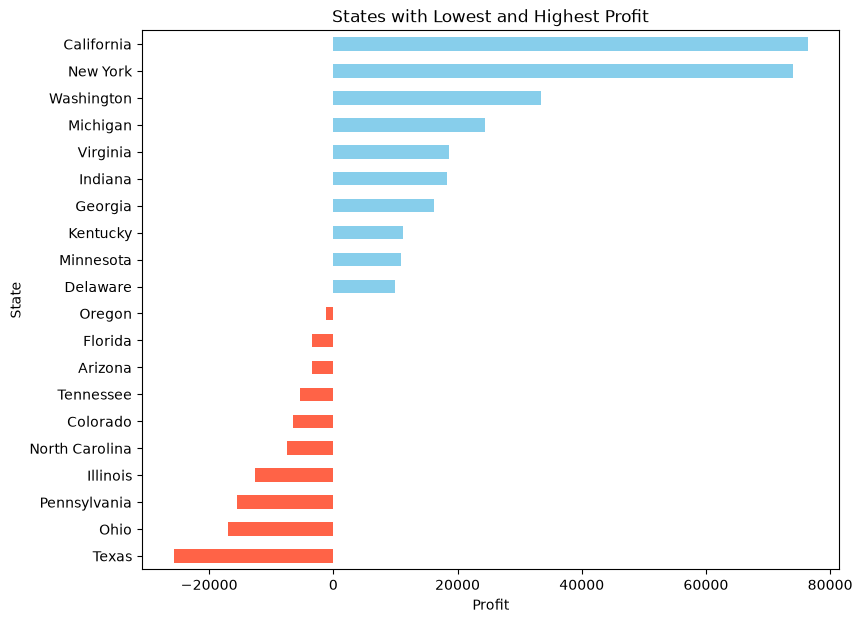

Estados con pérdidas: 10 de 49


In [107]:
estado = data.groupby("State")["Profit"].sum().sort_values()
extremos = pd.concat([estado.head(10), estado.tail(10)])

plt.figure(figsize=(9, 7))
extremos.plot(kind="barh", color=["tomato" if v < 0 else "skyblue" for v in extremos])
plt.title("States with Lowest and Highest Profit")
plt.xlabel("Profit")
plt.show()

print("Estados con pérdidas:", (estado < 0).sum(), "de", len(estado))

In [108]:
segmento = data.groupby("Segment").agg(ventas=("Sales", "sum"), utilidad=("Profit", "sum"))
segmento["margen"] = segmento["utilidad"] / segmento["ventas"]
segmento

,ventas,utilidad,margen
Segment,,,
Consumer,1.161401e+06,134119.2092,0.115481
Corporate,7.061464e+05,91979.1340,0.130255
Home Office,4.296531e+05,60298.6785,0.140343


## Tiempo de envío por modo de envío

Antes se vio el tiempo de envío promedio por mes. Aquí se ve cómo depende del modo de envío.

In [109]:
data.groupby("Ship Mode")["tiempo_envio"].agg(["mean", "min", "max"]).sort_values("mean")

,mean,min,max
Ship Mode,,,
Same Day,0.044199,0,1
First Class,2.182705,1,4
Second Class,3.238046,1,5
Standard Class,5.006535,3,7


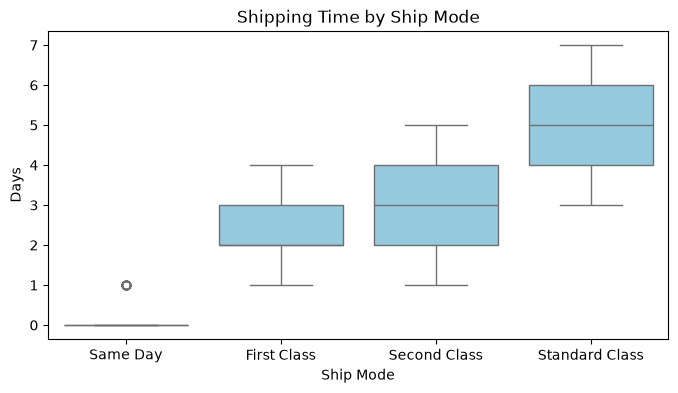

In [110]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=data, x="Ship Mode", y="tiempo_envio", order=["Same Day", "First Class", "Second Class", "Standard Class"], color="skyblue")
plt.title("Shipping Time by Ship Mode")
plt.ylabel("Days")
plt.show()

## Conclusiones

- Las ventas crecen cada año desde 2015 y el último trimestre del año concentra cerca del 38 % de las ventas.
- Furniture vende casi lo mismo que las otras categorías, pero con un margen mucho menor (alrededor de 2,5 % frente a ~17 %).
- Tables, Bookcases y Supplies tienen utilidad negativa.
- Los descuentos de más de 20 % están asociados a utilidad negativa; sin descuento el margen es cercano a 30 %.
- La región Central tiene el descuento promedio más alto y el menor margen, y 10 de los 49 estados tienen pérdidas.
- El tiempo de envío se mantiene estable (~4 días) y depende sobre todo del modo de envío.
